# Fine-tune Qwen Coder on Unity Project Q&A

**Model:** [Qwen/Qwen2.5-Coder-7B-Instruct](https://huggingface.co/Qwen/Qwen2.5-Coder-7B-Instruct) (7.61B parameters). **Method:** four-bit QLoRA, one epoch, answer-token supervision. Training and test CSVs are bundled; upload only this notebook.

## Run on Colab or Kaggle
- **Colab website:** upload this notebook, select a CUDA GPU runtime (T4 or better), then Run all.
- **Kaggle:** import this notebook, enable a GPU and Internet, then Run All.
- Run in a **fresh runtime** to avoid incompatible packages left by earlier experiments. Internet is required for dependencies and model weights. No token is required for this public default model.

The experiment measures the base model first, trains once, saves/reloads the adapter, then measures the adapted model. Test labels never enter training or prompts. No model upload or paid GPU provisioning occurs. Run this notebook on the website; its Colab download cell uses the browser UI.

Your earlier saved Qwen Coder run scored **182/269 (67.66%)**. This notebook measures its own base reference under the same environment and decoding as its adapted model; improvement is not guaranteed.


## 1. Install dependencies

Transformers and PEFT are pinned to the API versions used here. PyTorch comes from the GPU runtime. Exact installed versions are recorded. This notebook uses Transformers Trainer directly, avoiding dependencies on changing TRL trainer APIs.

References: [PEFT quantization guide](https://github.com/huggingface/peft/blob/v0.17.1/docs/source/developer_guides/quantization.md), [Transformers training guide](https://github.com/huggingface/transformers/blob/v4.57.3/docs/source/en/training.md).


In [1]:
%pip install -q "transformers==4.57.3" "peft==0.17.1" "accelerate>=1.0" "bitsandbytes>=0.45" sentencepiece matplotlib


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Check GPU and choose output location

Training uses a single GPU, including when Kaggle offers two. Four-bit frozen base weights and gradient checkpointing reduce memory use.


In [2]:
import os
from pathlib import Path
import torch
assert torch.cuda.is_available(), "Enable a GPU accelerator first."
if Path("/kaggle/working").is_dir():
    os.chdir("/kaggle/working")
elif Path("/content").is_dir():
    os.chdir("/content")
print("Working directory:", Path.cwd())
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory GiB:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1))


Working directory: /content
GPU: Tesla T4
GPU memory GiB: 14.6


## 3. Restore original datasets

Training data: **1,910 rows**, columns `class`, `Q`, `A`. Test data: **269 questions** with choices and labels. SHA-256 checks preserve the original files. Training uses only the training CSV; final evaluation uses the test CSV.


In [3]:
# Both original CSVs are bundled. Test answers are used for evaluation only.
import base64
import hashlib
from pathlib import Path
import zlib

bundled = {
    'TrainData.csv': {"sha256": '3150859588f37e4ec6b305ca8dce40726fed07b3a684ffbaaa70aec7c7dd61d3', "payload": (
        '...'
        'iCOGo/f/BUDhIzg='
    )},
    'TestData.csv': {"sha256": '5e10ec19d61624ee3554814337cf961fe499f4a666881c866c172fa1e51454a2', "payload": (
        '...'
    )},
}
for name, item in bundled.items():
    data = zlib.decompress(base64.b64decode(item["payload"]))
    assert hashlib.sha256(data).hexdigest() == item["sha256"]
    path = Path(name)
    if not path.exists():
        with path.open("xb") as handle:
            handle.write(data)
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item["sha256"], f"Existing {name} differs; rename it and rerun."
    print(f"Ready: {name} ({len(data):,} bytes)")


Ready: TrainData.csv (680,317 bytes)
Ready: TestData.csv (63,992 bytes)


## 4. Training decisions

- A seeded **90/10 split of normalized question groups** provides validation from training data. Identical question text stays together; semantic paraphrases may still cross the split. This validation loss does not measure unseen-project generalization.
- Training prompts include the C# script name and question. Targets are the supplied natural-language answers. Prompt/padding tokens are masked from loss. No synthetic MCQ answers are invented.
- **One epoch**, learning rate **1e-4**, batch size **1**, accumulation **16**, cosine schedule, 5% warmup. LoRA **rank 16**, alpha **32**, dropout **0.05**, on attention and MLP projections. These are starting settings, not claimed optimal settings.
- Maximum sequence length **2,048**. Overlength examples are recorded and excluded rather than cutting off their answers. Split indices, counts and token statistics are saved.
- Only the final one-epoch adapter is evaluated; no test-based checkpoint selection. The test is used for before/after reporting, so disclose test reuse and use training-derived validation for later development.
- Training targets are free-form Q&A, while evaluation is MCQ. Instruction-format failures remain visible in the score. A gain may reflect retained facts, format changes, or generalization; raw responses are saved to investigate.

If memory runs out, restart the runtime and lower `MAX_LENGTH` to 1,024. That changes which examples are included; retain the run metadata when comparing results.


In [4]:
MAX_LENGTH = 2048
SEED = 42


## 5. Write the included evaluator and training program

The original assessment notebook and its fixed `test_model` function are untouched. This separate evaluator uses the same question/choice prompt and strict answer parser as our zero-shot benchmark, one greedy generation per question and 128 output tokens. Missing or malformed answers count as wrong.


In [5]:
%%writefile benchmark.py
"""Zero-shot MCQ baseline. No training or training-data access."""

import argparse
import csv
import hashlib
import importlib.metadata
import json
from pathlib import Path
import re
import time


def build_prompt(row):
    choices = "\n".join(f"{key}) {row[key]}" for key in "abcd")
    return (
        "Answer the following multiple-choice question about a Unity C# game project.\n"
        "Choose the single best answer. End your response with Answer:a, Answer:b, "
        "Answer:c, or Answer:d.\n\n"
        f"{row['Question']}\n{choices}"
    )


def parse_answer(response):
    # An unfinished thinking block is not a final answer.
    if "<think>" in response and "</think>" not in response:
        return None
    final = response.rsplit("</think>", 1)[-1].strip()
    match = re.search(r"Answer\s*:\s*([abcd])\s*[.!]?\s*$", final, re.I)
    if match:
        return match.group(1).lower()
    return final.lower() if re.fullmatch(r"[abcd]", final, re.I) else None


def main(argv=None):
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--model", default="Qwen/Qwen3-4B")
    parser.add_argument("--data", type=Path, default=Path("TestData.csv"))
    parser.add_argument("--output", type=Path, required=True,
                        help="New directory for this run; existing directories are rejected.")
    parser.add_argument("--limit", type=int, help="First N rows for smoke checks only")
    parser.add_argument("--thinking", action="store_true", help="Qwen3 thinking mode")
    parser.add_argument("--max-new-tokens", type=int)
    parser.add_argument("--four-bit", action="store_true")
    parser.add_argument("--seed", type=int, default=42)
    args = parser.parse_args(argv)
    if args.limit is not None and args.limit < 1:
        parser.error("--limit must be positive")
    if args.max_new_tokens is not None and args.max_new_tokens < 1:
        parser.error("--max-new-tokens must be positive")
    if args.thinking and not args.model.startswith("Qwen/Qwen3-"):
        parser.error("--thinking is implemented only for Qwen3 models")
    with args.data.open(encoding="utf-8-sig", newline="") as handle:
        reader = csv.DictReader(handle)
        required = {"class", "Question", "a", "b", "c", "d", "Answer"}
        if not required.issubset(reader.fieldnames or []):
            parser.error("Unexpected test CSV schema")
        rows = list(reader)
    if args.limit:
        rows = rows[:args.limit]
    if not rows or any(row["Answer"].strip().lower() not in "abcd" or
                       len(row["Answer"].strip()) != 1 for row in rows):
        parser.error("Empty dataset or invalid answer labels")

    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, set_seed

    if not torch.cuda.is_available():
        raise RuntimeError("A CUDA GPU is required. Select a GPU runtime in Colab/Kaggle.")
    args.output.mkdir(parents=True, exist_ok=False)
    set_seed(args.seed)
    tokenizer = AutoTokenizer.from_pretrained(args.model)
    config = {"device_map": "auto", "torch_dtype": torch.float16}
    if args.four_bit:
        config["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True,
        )
    model = AutoModelForCausalLM.from_pretrained(args.model, **config).eval()
    max_tokens = args.max_new_tokens or (2048 if args.thinking else 128)
    generation = {"max_new_tokens": max_tokens, "do_sample": args.thinking,
                  "pad_token_id": tokenizer.pad_token_id or tokenizer.eos_token_id}
    if args.thinking:
        generation.update(temperature=0.6, top_p=0.95, top_k=20)
    metadata = {
        "model": args.model, "model_commit": getattr(model.config, "_commit_hash", None),
        "dataset_sha256": hashlib.sha256(args.data.read_bytes()).hexdigest(),
        "rows": len(rows), "smoke_test": args.limit is not None, "seed": args.seed,
        "thinking": args.thinking, "four_bit": args.four_bit, "generation": generation,
        "gpu": torch.cuda.get_device_name(0), "prompt_example": build_prompt(rows[0]),
        "versions": {p: importlib.metadata.version(p) for p in
                     ["torch", "transformers", "accelerate", "bitsandbytes"]},
        "protocol": "Zero-shot; no training examples or source code; invalid answers count as wrong.",
    }
    (args.output / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    predictions = []
    start = time.perf_counter()
    with (args.output / "predictions.jsonl").open("x", encoding="utf-8") as handle:
        for index, row in enumerate(rows):
            messages = [{"role": "user", "content": build_prompt(row)}]
            template_args = {}
            if args.model.startswith("Qwen/Qwen3-"):
                template_args["enable_thinking"] = args.thinking
            text = tokenizer.apply_chat_template(
                messages, tokenize=False, add_generation_prompt=True, **template_args)
            inputs = tokenizer(text, return_tensors="pt", add_special_tokens=False).to(model.device)
            tick = time.perf_counter()
            with torch.inference_mode():
                output = model.generate(**inputs, **generation)
            generated = output[0, inputs.input_ids.shape[1]:]
            response = tokenizer.decode(generated, skip_special_tokens=True)
            answer = parse_answer(response)
            result = {
                "row": index, "class": row["class"], "question": row["Question"],
                "response": response, "prediction": answer,
                "truth": row["Answer"].strip().lower(),
                "correct": answer == row["Answer"].strip().lower(),
                "seconds": time.perf_counter() - tick,
                "generated_tokens": len(generated),
                "token_budget_reached": len(generated) >= max_tokens,
            }
            predictions.append(result)
            handle.write(json.dumps(result, ensure_ascii=False) + "\n")
            handle.flush()
            print(f"{index + 1}/{len(rows)} correct={sum(p['correct'] for p in predictions)}", flush=True)
    correct = sum(p["correct"] for p in predictions)
    labels = {key: sum(p["truth"] == key for p in predictions) for key in "abcd"}
    summary = {
        "model": args.model, "questions": len(rows), "correct": correct,
        "accuracy": correct / len(rows),
        "invalid_answers": sum(p["prediction"] is None for p in predictions),
        "token_budget_reached": sum(p["token_budget_reached"] for p in predictions),
        "uniform_random_expected_accuracy": 0.25,
        "label_counts": labels, "constant_choice_accuracy": {k: v / len(rows) for k, v in labels.items()},
        "elapsed_seconds": time.perf_counter() - start,
        "smoke_test": args.limit is not None,
    }
    (args.output / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    print(json.dumps(summary, indent=2))


if __name__ == "__main__":
    main()


Writing benchmark.py


In [6]:
%%writefile finetune_qwen_coder.py
"""One-epoch QLoRA experiment; test labels never enter training or prompts."""

import argparse
from collections import defaultdict
import csv
import gc
import hashlib
import importlib.metadata
import json
import math
import os
from pathlib import Path
import random
import re
import time

os.environ.setdefault("USE_TF", "0")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

from benchmark import build_prompt, parse_answer

MODEL_ID = "Qwen/Qwen2.5-Coder-7B-Instruct"


def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")


def read_csv(path, required):
    with Path(path).open(encoding="utf-8-sig", newline="") as handle:
        reader = csv.DictReader(handle)
        if not set(required).issubset(reader.fieldnames or []):
            raise ValueError(f"Unexpected CSV schema: {path}")
        rows = list(reader)
    if not rows or any(not str(row.get(key) or "").strip() for row in rows for key in required):
        raise ValueError(f"Empty rows or required fields: {path}")
    return rows


def split_training_rows(rows, seed=42, validation_fraction=0.1):
    # Keep identical questions together even if class names or answers differ.
    groups = defaultdict(list)
    for index, row in enumerate(rows):
        question = re.sub(r"\s+", " ", row["Q"].strip().casefold())
        groups[question].append(index)
    keys = sorted(groups)
    random.Random(seed).shuffle(keys)
    validation_keys = set(keys[:max(1, round(len(keys) * validation_fraction))])
    validation_indices = sorted(i for key in validation_keys for i in groups[key])
    validation_set = set(validation_indices)
    training_indices = [i for i in range(len(rows)) if i not in validation_set]
    if not training_indices or not validation_indices:
        raise ValueError("Need enough distinct questions for train/validation splitting")
    return training_indices, validation_indices


def tokenize_example(row, tokenizer, max_length):
    user = f"In this Unity game project, regarding {row['class'].strip()}:\n{row['Q'].strip()}"
    messages = [{"role": "user", "content": user}]
    prefix = tokenizer.apply_chat_template(messages, tokenize=True, add_generation_prompt=True)
    full = tokenizer.apply_chat_template(
        messages + [{"role": "assistant", "content": row["A"].strip()}],
        tokenize=True, add_generation_prompt=False,
    )
    if full[:len(prefix)] != prefix:
        raise ValueError("Chat-template prefix mismatch; refusing incorrect loss masking")
    if len(full) > max_length:
        return None, len(full)
    labels = [-100] * len(prefix) + full[len(prefix):]
    if not any(label != -100 for label in labels):
        raise ValueError("Example contains no answer tokens")
    return {"input_ids": full, "attention_mask": [1] * len(full), "labels": labels}, len(full)


def collate_examples(examples, pad_token_id):
    import torch
    width = math.ceil(max(len(row["input_ids"]) for row in examples) / 8) * 8
    batch = {key: [] for key in ["input_ids", "attention_mask", "labels"]}
    for row in examples:
        padding = width - len(row["input_ids"])
        for key, pad in [("input_ids", pad_token_id), ("attention_mask", 0), ("labels", -100)]:
            batch[key].append(row[key] + [pad] * padding)
    return {key: torch.tensor(value, dtype=torch.long) for key, value in batch.items()}


def evaluate_mcq(model, tokenizer, rows, output):
    import torch
    output.mkdir(parents=True, exist_ok=False)
    model.eval()
    model.config.use_cache = True
    predictions = []
    torch.cuda.synchronize()
    start = time.perf_counter()
    with (output / "predictions.jsonl").open("x", encoding="utf-8") as handle:
        for index, row in enumerate(rows):
            prompt = build_prompt(row)
            text = tokenizer.apply_chat_template(
                [{"role": "user", "content": prompt}],
                tokenize=False, add_generation_prompt=True,
            )
            inputs = tokenizer(text, add_special_tokens=False, return_tensors="pt").to(model.device)
            tick = time.perf_counter()
            with torch.inference_mode():
                generated = model.generate(
                    **inputs, do_sample=False, max_new_tokens=128,
                    pad_token_id=tokenizer.pad_token_id,
                )[0, inputs.input_ids.shape[1]:]
            response = tokenizer.decode(generated, skip_special_tokens=True)
            answer = parse_answer(response)
            result = {
                "row": index, "class": row["class"], "question": row["Question"],
                "response": response, "prediction": answer, "truth": row["Answer"].strip().lower(),
                "correct": answer == row["Answer"].strip().lower(),
                "generated_tokens": len(generated), "token_budget_reached": len(generated) >= 128,
                "seconds": time.perf_counter() - tick,
            }
            predictions.append(result)
            handle.write(json.dumps(result, ensure_ascii=False) + "\n")
            handle.flush()
            if (index + 1) % 10 == 0 or index + 1 == len(rows):
                print(f"{output.name}: {index + 1}/{len(rows)}", flush=True)
    summary = {
        "model": MODEL_ID, "questions": len(rows),
        "correct": sum(row["correct"] for row in predictions),
        "accuracy": sum(row["correct"] for row in predictions) / len(rows),
        "invalid_answers": sum(row["prediction"] is None for row in predictions),
        "token_budget_reached": sum(row["token_budget_reached"] for row in predictions),
        "elapsed_seconds": time.perf_counter() - start,
    }
    write_json(output / "summary.json", summary)
    with (output / "predictions.csv").open("x", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(predictions[0]))
        writer.writeheader()
        writer.writerows(predictions)
    return summary, predictions


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--train", type=Path, default=Path("TrainData.csv"))
    parser.add_argument("--test", type=Path, default=Path("TestData.csv"))
    parser.add_argument("--output", type=Path, required=True)
    parser.add_argument("--max-length", type=int, default=2048)
    parser.add_argument("--seed", type=int, default=42)
    args = parser.parse_args()
    if args.max_length < 64:
        parser.error("--max-length must be at least 64")
    train_rows = read_csv(args.train, ["class", "Q", "A"])
    test_rows = read_csv(args.test, ["class", "Question", "a", "b", "c", "d", "Answer"])
    if any(row["Answer"].strip().lower() not in list("abcd") for row in test_rows):
        raise ValueError("Invalid MCQ answer label")

    import torch
    from functools import partial
    from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, Trainer, TrainingArguments, set_seed

    if not torch.cuda.is_available():
        raise RuntimeError("Enable a CUDA GPU before running this experiment")
    args.output.mkdir(parents=True, exist_ok=False)
    set_seed(args.seed)
    training_indices, validation_indices = split_training_rows(train_rows, args.seed)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "right"
    prepared = {}
    lengths = []
    exclusions = []
    for index, row in enumerate(train_rows):
        example, length = tokenize_example(row, tokenizer, args.max_length)
        lengths.append(length)
        if example is None:
            exclusions.append({"row": index, "class": row["class"], "tokens": length,
                               "reason": "Exceeds max_length; excluded without truncating answers"})
        else:
            prepared[index] = example
    training_indices = [i for i in training_indices if i in prepared]
    validation_indices = [i for i in validation_indices if i in prepared]
    if not training_indices or not validation_indices:
        raise ValueError("No usable training or validation examples after length checks")
    write_json(args.output / "split.json", {
        "seed": args.seed, "train_indices": training_indices,
        "validation_indices": validation_indices, "excluded": exclusions,
        "note": "Grouped by identical normalized question. Semantic paraphrases may still overlap.",
    })
    quantization = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True,
    )
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID, quantization_config=quantization, dtype=torch.float16,
        device_map={"": 0}, attn_implementation="sdpa",
    )
    revision = getattr(model.config, "_commit_hash", None)
    training_settings = {
        "num_train_epochs": 1, "learning_rate": 1e-4, "batch_size": 1,
        "gradient_accumulation_steps": 16, "warmup_ratio": 0.05,
        "lr_scheduler_type": "cosine", "weight_decay": 0.01,
        "max_grad_norm": 0.3, "lora_r": 16, "lora_alpha": 32,
        "lora_dropout": 0.05, "max_length": args.max_length,
    }
    metadata = {
        "model": MODEL_ID, "model_commit": revision, "seed": args.seed,
        "gpu": torch.cuda.get_device_name(0), "gpu_count_used": 1,
        "train_sha256": hashlib.sha256(args.train.read_bytes()).hexdigest(),
        "test_sha256": hashlib.sha256(args.test.read_bytes()).hexdigest(),
        "train_rows": len(train_rows), "train_examples_used": len(training_indices),
        "validation_examples": len(validation_indices), "test_rows": len(test_rows),
        "excluded_long_examples": len(exclusions),
        "train_token_lengths": {"min": min(lengths), "max": max(lengths), "mean": sum(lengths)/len(lengths)},
        "settings": training_settings,
        "versions": {p: importlib.metadata.version(p) for p in
                     ["torch", "transformers", "peft", "accelerate", "bitsandbytes"]},
        "protocol": "One epoch on training split only. Answer-only loss. Test evaluated once before and once after training, never used for selection. Fresh base and adapter share decoding and packages.",
        "evaluation": {"max_new_tokens": 128, "do_sample": False,
                       "invalid_answers_count_as_wrong": True, "prompt_example": build_prompt(test_rows[0])},
    }
    write_json(args.output / "metadata.json", metadata)
    print(f"Training: {len(training_indices)}; validation: {len(validation_indices)}; exclusions: {len(exclusions)}", flush=True)
    print("Measuring a fresh base-model reference with the same environment...", flush=True)
    base_summary, base_predictions = evaluate_mcq(model, tokenizer, test_rows, args.output / "base")

    # Reset stochastic state so training does not depend on evaluation RNG consumption.
    set_seed(args.seed)
    model.config.use_cache = False
    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
    model = get_peft_model(model, LoraConfig(
        r=16, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    ))
    model.print_trainable_parameters()
    trainable, total = model.get_nb_trainable_parameters()
    metadata.update(trainable_parameters=trainable, total_parameters=total)
    write_json(args.output / "metadata.json", metadata)
    training_args = TrainingArguments(
        output_dir=str(args.output / "training"), num_train_epochs=1,
        learning_rate=1e-4, per_device_train_batch_size=1, per_device_eval_batch_size=1,
        gradient_accumulation_steps=16, gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        fp16=True, optim="paged_adamw_8bit", lr_scheduler_type="cosine",
        warmup_ratio=0.05, weight_decay=0.01, max_grad_norm=0.3,
        logging_steps=5, eval_strategy="epoch", save_strategy="no",
        prediction_loss_only=True, report_to="none", seed=args.seed, data_seed=args.seed,
        dataloader_num_workers=0, remove_unused_columns=False,
    )
    trainer = Trainer(
        model=model, args=training_args,
        train_dataset=[prepared[i] for i in training_indices],
        eval_dataset=[prepared[i] for i in validation_indices],
        processing_class=tokenizer,
        data_collator=partial(collate_examples, pad_token_id=tokenizer.pad_token_id),
    )
    torch.cuda.reset_peak_memory_stats()
    trained = trainer.train()
    write_json(args.output / "training_metrics.json", {
        **trained.metrics, "peak_gpu_allocated_gib": torch.cuda.max_memory_allocated()/1024**3,
    })
    write_json(args.output / "training_log.json", trainer.state.log_history)
    adapter_path = args.output / "adapter"
    model.save_pretrained(adapter_path, safe_serialization=True)
    tokenizer.save_pretrained(adapter_path)

    # Reload from disk before final scoring, verifying adapter portability.
    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()
    base = AutoModelForCausalLM.from_pretrained(
        MODEL_ID, revision=revision, quantization_config=quantization,
        dtype=torch.float16, device_map={"": 0}, attn_implementation="sdpa",
    )
    model = PeftModel.from_pretrained(base, str(adapter_path), is_trainable=False)
    tuned_summary, tuned_predictions = evaluate_mcq(model, tokenizer, test_rows, args.output / "finetuned")
    comparison = {
        "base": base_summary, "finetuned": tuned_summary,
        "accuracy_change_percentage_points": 100*(tuned_summary["accuracy"]-base_summary["accuracy"]),
        "relative_accuracy_change": (tuned_summary["accuracy"]-base_summary["accuracy"])/base_summary["accuracy"] if base_summary["accuracy"] else None,
        "wrong_to_correct": sum(not a["correct"] and b["correct"] for a,b in zip(base_predictions,tuned_predictions)),
        "correct_to_wrong": sum(a["correct"] and not b["correct"] for a,b in zip(base_predictions,tuned_predictions)),
        "saved_adapter_reload_verified": True,
    }
    write_json(args.output / "comparison.json", comparison)
    print(json.dumps(comparison, indent=2), flush=True)
    print(f"Completed. Adapter and results: {args.output}", flush=True)


if __name__ == "__main__":
    main()


Writing finetune_qwen_coder.py


## 6. Run the complete experiment

This cell downloads/loads the model, measures the base reference, trains for one epoch, saves/reloads the adapter and scores the same test set. The validation pass measures loss without updates. Each invocation creates a new output directory.


In [7]:
import subprocess
import sys
from datetime import datetime, timezone

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN_DIR = str(Path("qlora-results") / f"qwen25-coder-7b-{stamp}")
command = [sys.executable, "-u", "finetune_qwen_coder.py", "--output", RUN_DIR,
           "--max-length", str(MAX_LENGTH), "--seed", str(SEED)]
print(f"Results and adapter: {RUN_DIR}", flush=True)
print("Stages: load model > base evaluation > one epoch > save/reload adapter > final evaluation.", flush=True)
with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                      text=True, bufsize=1) as process:
    for line in process.stdout:
        print(line, end="", flush=True)
    exit_code = process.wait()
if exit_code:
    raise RuntimeError(f"Experiment failed with exit code {exit_code}. See the error above; saved files remain on the runtime.")


Results and adapter: qlora-results/qwen25-coder-7b-20261113T053732139734Z
Stages: load model > base evaluation > one epoch > save/reload adapter > final evaluation.

Fetching 4 files: 100%|██████████| 4/4 [01:57<00:00, 29.47s/it] 

Loading checkpoint shards: 100%|██████████| 4/4 [01:07<00:00, 16.83s/it]
Training: 1718; validation: 192; exclusions: 0
Measuring a fresh base-model reference with the same environment...
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
base: 10/269
base: 20/269
base: 30/269
base: 40/269
base: 50/269
base: 60/269
base: 70/269
base: 80/269
base: 90/269
base: 100/269
base: 110/269
base: 120/269
base: 130/269
base: 140/269
base: 150/269
base: 160/269
base: 170/269
base: 180/269
base: 190/269
base: 200/269
base: 210/269
base: 220/269
base: 230/269
base: 240/269
base: 250/269
base: 260/269
base: 269/269
trainable params: 40,370,176 || all params: 7,655,986,688 |

## 7. Compare measured results

Accuracy includes invalid answers as wrong. Inspect both corrected and newly wrong questions before attributing a change to better project knowledge. A single run does not establish statistical reliability.


In [8]:
import json
from IPython.display import Markdown, display

comparison = json.loads((Path(RUN_DIR) / "comparison.json").read_text())
base, tuned = comparison["base"], comparison["finetuned"]
display(Markdown(
    "## Measured before/after results\n\n"
    "| Metric | Base | Fine-tuned |\n|---|---:|---:|\n"
    f"| Accuracy | {base['accuracy']:.2%} | {tuned['accuracy']:.2%} |\n"
    f"| Correct / questions | {base['correct']}/{base['questions']} | {tuned['correct']}/{tuned['questions']} |\n"
    f"| Invalid answers | {base['invalid_answers']} | {tuned['invalid_answers']} |\n"
    f"| Token budget reached | {base['token_budget_reached']} | {tuned['token_budget_reached']} |\n\n"
    f"Accuracy change: **{comparison['accuracy_change_percentage_points']:+.2f} percentage points**.\n\n"
    f"Wrong to correct: {comparison['wrong_to_correct']}; correct to wrong: {comparison['correct_to_wrong']}."
))
print("Saved adapter reloaded for final scoring:", comparison["saved_adapter_reload_verified"])


## Measured before/after results

| Metric | Base | Fine-tuned |
|---|---:|---:|
| Accuracy | 67.66% | 42.75% |
| Correct / questions | 182/269 | 115/269 |
| Invalid answers | 24 | 109 |
| Token budget reached | 2 | 0 |

Accuracy change: **-24.91 percentage points**.

Wrong to correct: 20; correct to wrong: 87.

Saved adapter reloaded for final scoring: True


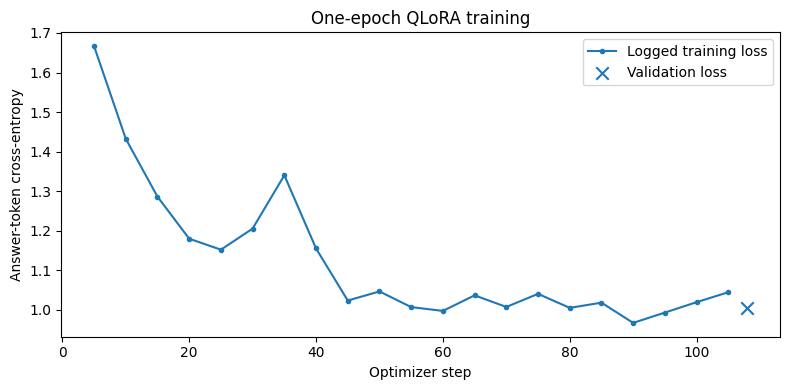

In [9]:
import matplotlib.pyplot as plt

history = json.loads((Path(RUN_DIR) / "training_log.json").read_text())
training_points = [(row["step"], row["loss"]) for row in history if "loss" in row]
validation_points = [(row["step"], row["eval_loss"]) for row in history if "eval_loss" in row]
fig, ax = plt.subplots(figsize=(8, 4))
if training_points:
    ax.plot(*zip(*training_points), marker=".", label="Logged training loss")
if validation_points:
    ax.scatter(*zip(*validation_points), marker="x", s=80, label="Validation loss")
ax.set(xlabel="Optimizer step", ylabel="Answer-token cross-entropy", title="One-epoch QLoRA training")
ax.legend()
fig.tight_layout()
fig.savefig(Path(RUN_DIR) / "loss.png", dpi=160)
plt.show()


## 8. Save the adapter and all evidence

The ZIP contains adapter weights/tokenizer, training/validation indices, excluded rows, losses, package versions, model revision, data hashes, both sets of raw responses and a before/after comparison. Base weights are not bundled. Keep the ZIP outside the temporary runtime.


In [10]:
import shutil
from IPython.display import FileLink, display

for script in ["finetune_qwen_coder.py", "benchmark.py"]:
    shutil.copyfile(script, Path(RUN_DIR) / script)
archive = shutil.make_archive(RUN_DIR, "zip", RUN_DIR)
print("Saved adapter and results:", Path(archive).resolve())
if Path("/kaggle/working").is_dir():
    display(FileLink(archive))
    print("Download the ZIP from Kaggle output files. Save a version with outputs to retain artifacts.")
else:
    from google.colab import files
    files.download(archive)


Saved adapter and results: /content/qlora-results/qwen25-coder-7b-20261113T053732139734Z.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Optional interactive demo

After the experiment, enable the cell below to load the saved adapter and define `ask_project(question)`. The automatic final test evaluation has already verified adapter reload. Open-ended responses may still be incorrect; compare them with project evidence.


In [11]:
# Optional: set True and run this cell after the experiment to try your saved adapter.
RUN_DEMO = False
if RUN_DEMO:
    import torch
    from peft import PeftModel
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
    saved = json.loads((Path(RUN_DIR) / "metadata.json").read_text())
    demo_tokenizer = AutoTokenizer.from_pretrained(Path(RUN_DIR) / "adapter")
    demo_base = AutoModelForCausalLM.from_pretrained(
        saved["model"], revision=saved["model_commit"], device_map={"": 0}, dtype=torch.float16,
        quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True),
    )
    demo_model = PeftModel.from_pretrained(demo_base, str(Path(RUN_DIR) / "adapter")).eval()
    def ask_project(question):
        text = demo_tokenizer.apply_chat_template([{"role": "user", "content": question}], tokenize=False, add_generation_prompt=True)
        inputs = demo_tokenizer(text, add_special_tokens=False, return_tensors="pt").to(demo_model.device)
        with torch.inference_mode():
            output = demo_model.generate(**inputs, max_new_tokens=256, do_sample=False, pad_token_id=demo_tokenizer.pad_token_id)
        return demo_tokenizer.decode(output[0, inputs.input_ids.shape[1]:], skip_special_tokens=True)
    print(ask_project("What is the purpose of the BeastAttack class in this Unity project?"))
    # After this cell, call ask_project("your question") in another cell.
